<a href="https://colab.research.google.com/github/ereanoor/G1A024075_R.-Noor-Fikhri_Seminar/blob/main/Webinar_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 🌍 ALUR AI & SATELLITE IMAGERY UNTUK DEFORESTASI
 1. Pengumpulan Citra Satelit Resolusi Tinggi (Remote Sensing)
 2. Preprocessing (Normalisasi RGB, Resizing ke Format Array)
 3. Ekstraksi Fitur Geospasial (Convolutional Neural Networks / CNN)
 4. Klasifikasi Pemicu (Sawit, Penebangan, Karhutla, Infrastruktur)

📌 Dimensi Data Latih (Training Set): (200, 64, 64, 3)
📌 Dimensi Data Uji  (Testing Set): (50, 64, 64, 3)

⏳ Membangun dan Melatih Model AI (Convolutional Neural Network)...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 186ms/step - accuracy: 0.2800 - loss: 1.5608 - val_accuracy: 0.1200 - val_loss: 1.4065
Epoch 2/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 158ms/step - accuracy: 0.2200 - loss: 1.3868 - val_accuracy: 0.1200 - val_loss: 1.4012
Epoch 3/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 256ms/step - accuracy: 0.2800 - loss: 1.3757 - val_accuracy: 0.1200 - val_loss: 1.4301
Epoch 4/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 151ms/step - accuracy: 0.2600 - loss: 1.3794 - val_accuracy: 0.1200 - val_loss: 1.4753
Epoch 5/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 147ms/step - accuracy: 0.2700 - loss: 1.3968 - val_accuracy: 0.1200 - val_loss: 1.4156

✅ Pelatihan Model Selesai!

📊 Melakukan Prediksi Pemicu Deforestasi pada Data Uji...
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step


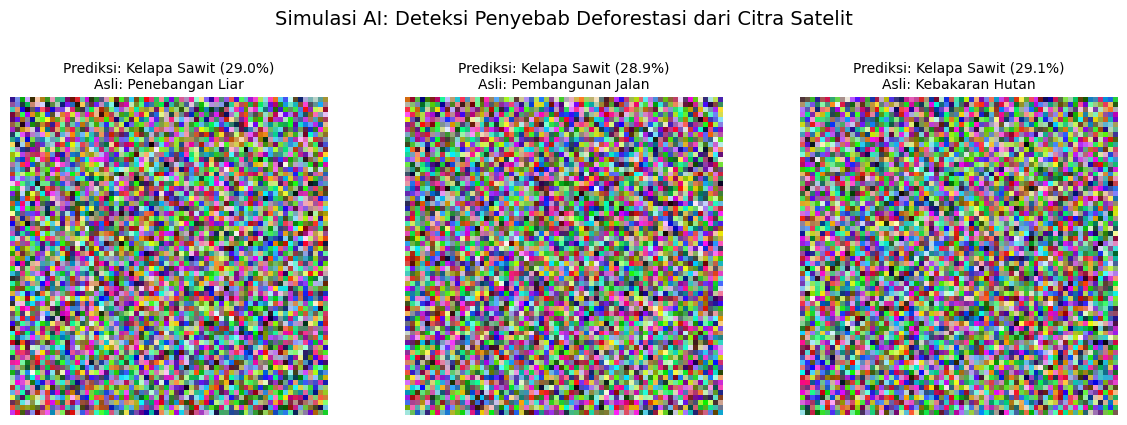


💡 KESIMPULAN MATERI 6:
 Melalui kombinasi citra satelit dan algoritma Deep Learning (CNN), sistem
 dapat mengekstraksi fitur visual/spasial (seperti pola lahan atau warna tutupan)
 untuk mengatribusikan penyebab hilangnya tutupan hutan secara otomatis.


In [1]:
# ==============================================================================
# INFORMATICS PRACTITIONER LECTURE SERIES 2026 - UNIB
# IMPLEMENTASI MATERI 6: Attributing Direct Drivers to Deforestation Alerts
# Topik: Pengolahan Citra Satelit & Deep Learning (CNN)
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# 1. SPESIFIKASI ALUR (PIPELINE) PENGOLAHAN CITRA SATELIT
print("=" * 65)
print(" 🌍 ALUR AI & SATELLITE IMAGERY UNTUK DEFORESTASI")
print("=" * 65)
print(" 1. Pengumpulan Citra Satelit Resolusi Tinggi (Remote Sensing)")
print(" 2. Preprocessing (Normalisasi RGB, Resizing ke Format Array)")
print(" 3. Ekstraksi Fitur Geospasial (Convolutional Neural Networks / CNN)")
print(" 4. Klasifikasi Pemicu (Sawit, Penebangan, Karhutla, Infrastruktur)")
print("=" * 65 + "\n")

# 2. GENERATE SYNTHETIC SATELLITE DATA (Simulasi Citra Satelit)
# (Di dunia nyata, data ini menggunakan library seperti rasterio / gdal dari citra Sentinel/Landsat)
np.random.seed(42)
tf.random.set_seed(42)

num_samples = 250
img_size = 64 # Resolusi simulasi 64x64 pixels
channels = 3  # RGB Channels

# Simulasi citra (Matriks piksel acak)
X_data = np.random.rand(num_samples, img_size, img_size, channels)

# Simulasi label kelas penyebab deforestasi
class_names = ['Kelapa Sawit', 'Penebangan Liar', 'Kebakaran Hutan', 'Pembangunan Jalan']
y_data = np.random.randint(0, 4, num_samples)

# Partitioning: Membagi Data Latih (80%) dan Data Uji (20%)
split_idx = int(0.8 * num_samples)
X_train, X_test = X_data[:split_idx], X_data[split_idx:]
y_train, y_test = y_data[:split_idx], y_data[split_idx:]

print(f"📌 Dimensi Data Latih (Training Set): {X_train.shape}")
print(f"📌 Dimensi Data Uji  (Testing Set): {X_test.shape}\n")

# 3. MEMBANGUN ARSITEKTUR MODEL DEEP LEARNING (CNN)
print("⏳ Membangun dan Melatih Model AI (Convolutional Neural Network)...")
model = Sequential([
    # Layer Konvolusi 1
    Conv2D(32, (3, 3), activation='relu', input_shape=(img_size, img_size, channels)),
    MaxPooling2D((2, 2)),

    # Layer Konvolusi 2
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Klasifikasi Layer (Dense)
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.3), # Mencegah overfitting
    Dense(4, activation='softmax') # 4 Output untuk kelas pemicu deforestasi
])

# Kompilasi Model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# 4. TRAINING SIMULATION (Dibatasi 5 Epoch agar cepat dieksekusi di Colab)
history = model.fit(X_train, y_train, epochs=5, validation_data=(X_test, y_test), verbose=1)

print("\n✅ Pelatihan Model Selesai!\n")

# 5. PREDIKSI DAN VISUALISASI HASIL AI
print("📊 Melakukan Prediksi Pemicu Deforestasi pada Data Uji...")
predictions = model.predict(X_test)

# Menampilkan 3 contoh simulasi citra satelit dan hasil klasifikasinya
plt.figure(figsize=(12, 4))
for i in range(3):
    plt.subplot(1, 3, i+1)

    # Render citra
    plt.imshow(X_test[i])

    # Mengambil probabilitas tertinggi sebagai kelas prediksi
    predicted_class = class_names[np.argmax(predictions[i])]
    actual_class = class_names[y_test[i]]
    confidence = np.max(predictions[i]) * 100

    plt.title(f"Prediksi: {predicted_class} ({confidence:.1f}%)\nAsli: {actual_class}", fontsize=10)
    plt.axis('off')

plt.suptitle("Simulasi AI: Deteksi Penyebab Deforestasi dari Citra Satelit", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

print("\n💡 KESIMPULAN MATERI 6:")
print(" Melalui kombinasi citra satelit dan algoritma Deep Learning (CNN), sistem")
print(" dapat mengekstraksi fitur visual/spasial (seperti pola lahan atau warna tutupan)")
print(" untuk mengatribusikan penyebab hilangnya tutupan hutan secara otomatis.")